# Projeto RAG Avançado · Família 3 (After searching) · Petrobras × Vale

**Versão v2** do notebook `lesson09_gerada_JP.ipynb` (o original continua intacto para comparação).
Mesmo corpus, mesmas 40 perguntas (16 `direct`, 16 `multi`, 8 `none`), mesmo harness. Aqui a F3 é estudada de verdade: diagnóstico do *lost in the middle* no baseline e quatro técnicas que mexem no que entra no prompt.

| Bloco | O que roda | Arquivo gerado em `results/` |
|---|---|---|
| 1 | Baseline k=4 (3 rodadas) e baseline de estresse k=12 | `baseline_r1/r2/r3.csv`, `results_baseline_k12.csv` |
| 2 | Reranking com cross-encoder (inglês da aula × multilíngue) | `results_rerank_en.csv`, `results_rerank_ml.csv` |
| 3 | Compressão de contexto | `results_compress.csv` |
| 4 | Ordering (melhor chunk nas pontas) | `results_order.csv`, `results_rerank_order.csv` |
| 5 | Variação de configuração do rerank (n = 20) | `results_rerank_ml_n20.csv` |
| 6 | Baseline com temperatura 0,3 (mede ruído) | `baseline_t03_r1/r2/r3.csv` |
| 7 | Tabela final, divergências, gráfico e `results_f3.zip` | `summary_table.csv`, `disagreements_*.csv`, `scoreboard.png` |

### O que mudou em relação ao notebook anterior
| # | Mudança | Por quê |
|---|---|---|
| 1 | `import shutil` antes de usar; clone feito com `subprocess` | A célula do corpus quebrava com `NameError` e deixava `corpus/` vazio |
| 2 | `REFUSAL` em português e comparação sem acento/maiúscula | O prompt manda recusar em português; o `grade` procurava a frase em inglês, então n01 e n02 davam sempre ✗ |
| 3 | Perguntas embutidas (`QUESTIONS_V2`) com `gold_docs` corrigidos e variantes de palavra-chave | O gold não batia com o conteúdo dos arquivos; "3 anos" e "5 anos" nem existem no texto (é "3 (três) anos") |
| 4 | Geração via `/api/chat` com `num_ctx = 16384` | Com k=12 o prompt passa de 4096 tokens e o Ollama corta o início em silêncio (inclusive o system prompt) |
| 5 | Reranker multilíngue (e o inglês da aula como comparação) | O `ms-marco-MiniLM` foi treinado em inglês; o corpus é em português |
| 6 | Novas técnicas F3: compressão e ordering | O PDF pede além do rerank |
| 7 | Novas colunas: `gold_all`, `gold_positions`, `ctx_tokens`, `run`, `temperature` | Diagnóstico por posição e custo em tokens |
| 8 | CSVs em `results/`, divergências, tabela final, zip | Estrutura exigida pelo PDF |
| 9 | Limpeza: sem `GROUNDING` duplicado, sem sobras da aula, rótulos do gráfico calculados | Clareza |

### Como rodar
1. Runtime → **Alterar tipo de ambiente de execução → T4 GPU**.
2. **Ambiente de execução → Executar tudo.** Leva uns 20 a 30 minutos.
3. No fim, baixe `results_f3.zip` (baixa sozinho; se não baixar, pegue pelo painel de arquivos) e coloque o conteúdo na pasta `results/` do repositório.

Se o Colab cair, rode de novo: CSVs que já existem são reaproveitados. Para refazer tudo, use `FORCE = True` na célula do Bloco 1.

---
## 🧰 Preparação no Colab (3 células, uns 4 minutos)

In [1]:
# Colab 1 · Instala o Ollama e sobe o servidor em segundo plano.
# !apt-get install -y -qq zstd > /dev/null 2>&1 || (apt-get update -qq > /dev/null 2>&1 && apt-get install -y -qq zstd > /dev/null 2>&1)
# !curl -fsSL https://ollama.com/install.sh | sh 2>&1 | tail -n 2

# import subprocess, time, requests
# OLLAMA_URL = "http://localhost:11434"
# def server_is_up():
#     try: return requests.get(f"{OLLAMA_URL}/api/version", timeout=2).ok
#     except requests.RequestException: return False
# if not server_is_up():
#     subprocess.Popen(["ollama", "serve"], stdout=open("ollama.log", "w"), stderr=subprocess.STDOUT, start_new_session=True)
#     for _ in range(30):
#         if server_is_up(): break
#         time.sleep(1)
# print("servidor no ar:", server_is_up())

In [2]:
# Local 1 · Verifica se o Ollama está instalado e sobe o servidor se necessário.
import shutil, subprocess, time, requests

OLLAMA_URL = "http://localhost:11434"

def server_is_up():
    try:
        return requests.get(f"{OLLAMA_URL}/api/version", timeout=2).ok
    except requests.RequestException:
        return False

if not server_is_up():
    if not shutil.which("ollama"):
        raise RuntimeError(
            "Ollama não encontrado no PATH! Instale com 'winget install Ollama.Ollama' "
            "ou em https://ollama.com/download e reinicie o VS Code/Jupyter."
        )
    subprocess.Popen(
        ["ollama", "serve"],
        stdout=open("ollama.log", "w"),
        stderr=subprocess.STDOUT,
    )
    for _ in range(30):
        if server_is_up():
            break
        time.sleep(1)

print("servidor no ar:", server_is_up())

servidor no ar: True


In [3]:
# Colab 2 · Baixa o gerador (qwen2.5:3b) e o modelo de embedding (nomic-embed-text).
#!ollama pull qwen2.5:3b
#!ollama pull nomic-embed-text
#!ollama list

In [4]:
# Colab 3 · Pacotes Python. O aviso vermelho sobre google-adk/opentelemetry é inofensivo.
#!pip -q install chromadb requests pandas numpy matplotlib sentence-transformers

---
## Núcleo do RAG clássico (aula 8)
Configuração, Load → Chunk → Embed → Store → Retrieve → Augment → Generate. Só duas mudanças em relação ao original: `generate` usa a API nativa do Ollama com `num_ctx` explícito, e `retrieve` devolve o id e a posição densa de cada chunk.

In [5]:
import os, re, glob, json, time, math, shutil, subprocess, unicodedata
import requests
import numpy as np
import pandas as pd
import chromadb

OLLAMA_URL  = "http://localhost:11434"
GEN_MODEL   = "qwen2.5:3b"            # o gerador. Troque por "qwen2.5:0.5b" se a máquina sofrer.
EMB_MODEL   = "nomic-embed-text"      # TEM de ser o mesmo na indexação e na consulta.
CORPUS_DIR  = "corpus"
CHROMA_DIR  = "chroma_lesson09"
RESULTS_DIR = "results"
NUM_CTX     = 12288                   # janela de contexto pedida ao Ollama (k=12 chega a ~8.5k tokens; 12k poupa VRAM)
os.makedirs(RESULTS_DIR, exist_ok=True)

# ---- tokens: aqui 1 token = 1 palavra (com o espaço que a precede). Tokenizadores reais produzem ~30-60% mais tokens.
def tokenize(text):     return re.findall(r"\s*\S+", text)
def detokenize(toks):   return "".join(toks).strip()
def count_tokens(text): return len(tokenize(text))

def norm(s):
    """Minúsculas, sem acento, espaços colapsados. Usada no grade e na validação das perguntas."""
    s = unicodedata.normalize("NFKD", str(s).lower())
    s = "".join(c for c in s if not unicodedata.combining(c))
    return re.sub(r"\s+", " ", s).strip()

# ---- Load
def load_corpus(folder=CORPUS_DIR):
    return [{"doc": os.path.basename(p), "text": open(p, encoding="utf-8").read()}
            for p in sorted(glob.glob(os.path.join(folder, "Arquivo*.md")))]

# ---- Chunk (tamanho fixo com overlap, em tokens)
def chunk_fixed(text, chunk_size=512, overlap=51):
    toks, step, out = tokenize(text), chunk_size - overlap, []
    for start in range(0, max(len(toks), 1), step):
        out.append(detokenize(toks[start:start + chunk_size]))
        if start + chunk_size >= len(toks):
            break
    return out

def make_chunks(docs, chunk_size=512, overlap=51):
    """Uma linha por chunk: id, texto e metadados (documento, posição, seção dominante)."""
    rows = []
    for d in docs:
        carried = "-"
        for i, c in enumerate(chunk_fixed(d["text"], chunk_size, overlap)):
            heads = [(m.start(), m.group(1)[:80]) for m in re.finditer(r"^#+ (.+)$", c, re.M)]
            first_half = [h for pos, h in heads if pos < len(c) / 2]
            section = first_half[-1] if first_half else carried
            if heads:
                carried = heads[-1][1]
            rows.append({"id": f"{d['doc']}#{i}", "text": c, "doc": d["doc"], "chunk": i, "section": section})
    return rows

# ---- Augment
GROUNDING = ("Você é o assistente especialista em governança, conformidade e políticas corporativas da Petrobras e da Vale. "
             "Responda à pergunta utilizando APENAS o contexto fornecido abaixo. "
             "Se o contexto não contiver a resposta, responda exatamente: \"Os documentos corporativos não cobrem esta informação.\" "
             "Cite a fonte de cada fato entre colchetes, como por exemplo [Arquivo1.md].")
FREE = "Você é o assistente especialista em governança, conformidade e políticas corporativas da Petrobras e da Vale. Responda à pergunta."

def build_prompt(question, hits, grounded=True):
    context = "\n\n".join(f"[{h['doc']} · {h['section']}]\n{h['text']}" for h in hits)
    system = GROUNDING if grounded else FREE
    user = f"Context:\n{context}\n\nQuestion: {question}" if hits else f"Question: {question}"
    return [{"role": "system", "content": system}, {"role": "user", "content": user}]

# ---- Embed (Ollama /api/embed devolve uma lista de vetores)
def embed(texts, model=EMB_MODEL, retries=4):
    for attempt in range(1, retries + 1):
        try:
            r = requests.post(f"{OLLAMA_URL}/api/embed", timeout=120, json={"model": model, "input": texts, "keep_alive": -1})
            r.raise_for_status()
            return r.json()["embeddings"]
        except requests.RequestException as e:
            if attempt == retries:
                raise
            print(f"  [retry] embed falhou (tentativa {attempt}/{retries}: {e}); aguardando {2*attempt}s...")
            time.sleep(2 * attempt)

# ---- Store (Chroma persistente, distância = 1 - cosseno)
def build_index(rows, name, persist_dir=CHROMA_DIR, batch=32, rebuild=False):
    store = chromadb.PersistentClient(path=persist_dir)
    if rebuild:
        try: store.delete_collection(name)
        except Exception: pass
    col = store.get_or_create_collection(name, metadata={"hnsw:space": "cosine", "embedding_model": EMB_MODEL})
    if col.count() == len(rows):
        return col
    for i in range(0, len(rows), batch):
        part = rows[i:i + batch]
        col.upsert(ids=[r["id"] for r in part], documents=[r["text"] for r in part],
                   embeddings=embed([r["text"] for r in part]),
                   metadatas=[{"doc": r["doc"], "chunk": r["chunk"], "section": r["section"]} for r in part])
    return col

# ---- Retrieve (denso). Devolve também id e posição densa de cada chunk.
def retrieve(col, question, k=4):
    assert col.metadata.get("embedding_model") == EMB_MODEL, "índice e consulta com modelos de embedding diferentes"
    res = col.query(query_embeddings=embed([question]), n_results=k, include=["documents", "metadatas", "distances"])
    return [{"id": i, "text": t, "doc": m["doc"], "section": m["section"], "distance": d, "dense_rank": r}
            for r, (i, t, m, d) in enumerate(zip(res["ids"][0], res["documents"][0], res["metadatas"][0], res["distances"][0]), 1)]

ROWS_BY_ID = {}
def register_rows(rows):
    ROWS_BY_ID.clear()
    ROWS_BY_ID.update({r["id"]: r for r in rows})

def hit_from_row(row, **extra):
    h = {"id": row["id"], "text": row["text"], "doc": row["doc"], "section": row["section"], "distance": float("nan")}
    h.update(extra)
    return h

def dense_ranking(col, text, n=10):
    res = col.query(query_embeddings=embed([text]), n_results=n, include=["distances"])
    return list(zip(res["ids"][0], res["distances"][0]))

# ---- Generate (API nativa do Ollama: permite num_ctx e seed, e conta as chamadas ao LLM)
LLM_CALLS = 0
LAST_PROMPT_EVAL = None
def generate(messages, model=GEN_MODEL, temperature=0.0, max_tokens=450, seed=None, num_ctx=NUM_CTX, retries=4):
    global LLM_CALLS, LAST_PROMPT_EVAL
    LLM_CALLS += 1
    opts = {"temperature": temperature, "num_predict": max_tokens, "num_ctx": num_ctx}
    if seed is not None:
        opts["seed"] = seed
    for attempt in range(1, retries + 1):
        t0 = time.time()
        try:
            r = requests.post(f"{OLLAMA_URL}/api/chat", timeout=900,
                              json={"model": model, "messages": messages, "stream": False, "options": opts, "keep_alive": -1})
            r.raise_for_status()
            j = r.json()
            LAST_PROMPT_EVAL = j.get("prompt_eval_count")      # tokens avaliados nesta chamada (o cache do Ollama pode reduzir)
            return j["message"]["content"].strip(), time.time() - t0
        except requests.RequestException as e:
            if attempt == retries:
                raise
            print(f"  [retry] generate falhou (tentativa {attempt}/{retries}: {e}); aguardando {3*attempt}s...")
            time.sleep(3 * attempt)

def warm_up():
    """Carrega os dois modelos na memória (já com o num_ctx certo) e mantém lá."""
    requests.post(f"{OLLAMA_URL}/api/embed", json={"model": EMB_MODEL, "input": "warm up", "keep_alive": -1}).raise_for_status()
    requests.post(f"{OLLAMA_URL}/api/generate", json={"model": GEN_MODEL, "prompt": "hi", "keep_alive": -1, "stream": False,
                                                       "options": {"num_predict": 1, "num_ctx": NUM_CTX}}).raise_for_status()
    for m in requests.get(f"{OLLAMA_URL}/api/ps").json().get("models", []):
        where = "GPU" if m.get("size_vram", 0) >= m.get("size", 1) * 0.9 else ("parcial GPU" if m.get("size_vram", 0) else "CPU")
        print(f"{m['name']:<24} carregado em {where}")

def show(hits, score_key="distance"):
    for i, h in enumerate(hits, 1):
        s = h.get(score_key, float("nan"))
        tag = f"({score_key} {s:.3f})" if isinstance(s, float) and not math.isnan(s) else ""
        print(f"[{i}] {h['doc']} · {h['section']}  {tag}")
        print("    " + h["text"][:140].replace("\n", " ") + " ...")

In [6]:
# Cronômetro automático: cada célula imprime o seu tempo (⏱) e registra em CELL_TIMES.
from IPython import get_ipython
CELL_TIMES = []
_ip = get_ipython()
if _ip is not None:
    def _pre_run(info): _ip._t0 = time.perf_counter()
    def _post_run(result):
        dt = time.perf_counter() - getattr(_ip, "_t0", time.perf_counter())
        first = (result.info.raw_cell.strip().splitlines() or [""])[0][:70]
        CELL_TIMES.append({"cell": first, "seconds": round(dt, 2)})
        print(f"⏱ {dt:.1f} s")
    if not getattr(_ip, "_timer_installed", False):
        _ip.events.register("pre_run_cell", _pre_run)
        _ip.events.register("post_run_cell", _post_run)
        _ip._timer_installed = True
print("cronômetro ligado")

cronômetro ligado
⏱ -0.0 s


---
## Corpus e perguntas
O corpus (corpus/) e as perguntas (questions.json) são carregados diretamente dos arquivos locais (ou baixados do repositório caso esteja rodando no Colab).

Mapa real do corpus: **1** Vale/Código de Conduta · **2** Petrobras/Código de Conduta · **3** Vale/Aviso de Privacidade · **4** Petrobras/Proteção de Dados · **5** Vale/Gestão de Riscos · **6** Petrobras/Gestão de Riscos.

must_contain aceita, em cada posição, um texto ou uma lista de alternativas (basta uma). O grade ignora acento e maiúscula.

In [7]:
#REPO_URL = "https://github.com/pabloart702/rag-f3-petrobras-vale.git"

# def fetch_repo(force=False):
#     """Baixa corpus/ e questions.json do repositório se ainda não estiverem presentes localmente."""
#     os.makedirs(CORPUS_DIR, exist_ok=True)
#     if glob.glob(os.path.join(CORPUS_DIR, "Arquivo*.md")) and os.path.exists("questions.json") and not force:
#         print("corpus e questions.json já presentes localmente")
#         return
#     if os.path.exists("temp_git"):
#         shutil.rmtree("temp_git")
#     subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "temp_git"], check=True)
#     for f in glob.glob("temp_git/corpus/*.md"):
#         shutil.copy(f, CORPUS_DIR)
#     if os.path.exists("temp_git/questions.json") and (force or not os.path.exists("questions.json")):
#         shutil.copy("temp_git/questions.json", "questions.json")
#     shutil.rmtree("temp_git")
#     print("arquivos baixados:", sorted(os.listdir(CORPUS_DIR)))

# fetch_repo()

⏱ 0.0 s


In [8]:
# Carrega as perguntas diretamente de questions.json (fonte única da verdade, sem sobrescrever o JSON)
with open("questions.json", encoding="utf-8") as f:
    QUESTIONS_V2 = json.load(f)
QUESTIONS = QUESTIONS_V2
questions = QUESTIONS
print(f"{len(QUESTIONS)} perguntas carregadas de questions.json")

40 perguntas carregadas de questions.json
⏱ 0.0 s


In [9]:
def validate_questions(questions, docs):
    """Confere: o gold existe e cada palavra-chave (alguma alternativa) aparece nos documentos gold."""
    text = {d["doc"]: norm(d["text"]) for d in docs}
    ok = True
    for q in questions:
        if q["expect_refusal"]:
            continue
        for g in q["gold_docs"]:
            if g not in text:
                print(f"  ✗ {q['id']}: gold {g} não existe no corpus"); ok = False
        blob = " ".join(text.get(g, "") for g in q["gold_docs"])
        for kw in q["must_contain"]:
            alts = kw if isinstance(kw, (list, tuple)) else [kw]
            if not any(norm(a) in blob for a in alts):
                print(f"  ✗ {q['id']}: nenhuma alternativa de {alts} aparece nos docs gold {q['gold_docs']}"); ok = False
    print("perguntas validadas contra o corpus:", "OK" if ok else "COM PROBLEMAS (veja acima)")
    return ok

docs = load_corpus()
tiers = pd.Series([q["tier"] for q in QUESTIONS]).value_counts().to_dict()
print(f"{len(docs)} documentos · {len(QUESTIONS)} perguntas · tiers {tiers}")
validate_questions(QUESTIONS, docs)
for q in QUESTIONS:
    if q.get("note"):
        print(f"  ⚠ {q['id']}: {q['note']}")

6 documentos · 40 perguntas · tiers {'direct': 16, 'multi': 16, 'none': 8}
perguntas validadas contra o corpus: OK
⏱ 0.0 s


---
## Harness v2
`grade` ignora acento e maiúscula, aceita alternativas e reconhece a recusa em português. `run_variant` grava, por pergunta, o que foi recuperado, em que posição estava cada documento gold, quantos tokens de contexto entraram no prompt, chamadas de LLM e latência ponta a ponta.

In [10]:
REFUSAL = norm("Os documentos corporativos não cobrem esta informação")
REFUSAL_CORE = "nao cobrem esta informacao"

def _kw_ok(answer_n, kw):
    alts = kw if isinstance(kw, (list, tuple)) else [kw]
    return any(norm(a) in answer_n for a in alts)

def grade(answer, q):
    """(acertou, recusou). Acerto = todas as palavras-chave presentes e sem recusa, ou recusa quando era esperada."""
    a = norm(answer)
    refused = REFUSAL in a or REFUSAL_CORE in a
    if q["expect_refusal"]:
        return refused, refused
    return all(_kw_ok(a, kw) for kw in q["must_contain"]) and not refused, refused

def run_variant(label, index, questions, retriever, k_info, temperature=0.0, run=1, seed=None, verbose=True):
    """retriever(index, pergunta) -> hits, na ordem em que entram no prompt."""
    global LLM_CALLS
    records = []
    n_total = len(questions)
    for idx_q, q in enumerate(questions, 1):
        LLM_CALLS = 0
        t0 = time.time()
        hits = retriever(index, q["question"])
        answer, _ = generate(build_prompt(q["question"], hits), temperature=temperature, seed=seed)
        total = time.time() - t0
        correct, refused = grade(answer, q)
        gold = set(q["gold_docs"])
        docs_hit = [h["doc"] for h in hits]
        gpos = [i for i, d in enumerate(docs_hit, 1) if d in gold]
        ctx_tok = sum(count_tokens(h["text"]) for h in hits)
        ctx_orig = sum(h.get("orig_tokens", count_tokens(h["text"])) for h in hits)
        if ctx_tok * 1.6 > NUM_CTX * 0.9:
            print(f"  ⚠ {q['id']}: ~{int(ctx_tok*1.6)} tokens estimados perto do limite num_ctx={NUM_CTX}")
        records.append({
            "label": label, "run": run, "temperature": temperature, "k": k_info,
            "id": q["id"], "tier": q["tier"], "question": q["question"],
            "retrieved_ids": "|".join(h["id"] for h in hits), "retrieved_docs": "|".join(docs_hit), "n_hits": len(hits),
            "gold_docs": "|".join(q["gold_docs"]),
            "gold_hit": bool(gpos), "gold_all": (gold.issubset(set(docs_hit)) if gold else None),
            "gold_rank": (gpos[0] if gpos else None), "gold_positions": "|".join(map(str, gpos)),
            "answer": answer, "correct": correct, "refused": refused,
            "llm_calls": LLM_CALLS, "latency_s": round(total, 2),
            "ctx_tokens": ctx_tok, "ctx_tokens_orig": ctx_orig, "prompt_eval_tokens": LAST_PROMPT_EVAL,
        })
        if verbose:
            print(f"{label:<14} [{idx_q:02d}/{n_total}] {q['id']} {'✓' if correct else '✗'}  {LLM_CALLS} call  {total:4.1f}s  ctx~{ctx_tok}")
        elif idx_q % 10 == 0 or idx_q == n_total:
            acc_so_far = sum(r["correct"] for r in records) / len(records)
            print(f"  [{label}] {idx_q}/{n_total} concluídas (acerto parcial: {acc_so_far:.2f})")
    return pd.DataFrame(records)

ORDER = ["baseline_r1", "baseline_r2", "baseline_r3", "baseline_k12", "rerank_en", "rerank_ml", "compress",
         "order", "rerank_order", "rerank_ml_n20", "baseline_t03_r1", "baseline_t03_r2", "baseline_t03_r3"]

def summarize(dfs):
    """Uma linha por variante: acerto por tier, geral, recuperação (só respondíveis), custo e latência."""
    df = pd.concat(dfs, ignore_index=True)
    df["correct"] = df["correct"].astype(float)
    ans = df[df["tier"] != "none"].copy()
    ans["gold_hit"] = ans["gold_hit"].astype(float)
    ans["gold_all"] = pd.to_numeric(ans["gold_all"].map({True: 1.0, False: 0.0, "True": 1.0, "False": 0.0}), errors="coerce")
    ans["g1"] = (pd.to_numeric(ans["gold_rank"], errors="coerce") == 1).astype(float)
    acc = df.pivot_table(index="label", columns="tier", values="correct", aggfunc="mean")
    for t in ["direct", "multi", "none"]:
        if t not in acc.columns: acc[t] = np.nan
    extra = df.groupby("label").agg(overall=("correct", "mean"), llm_calls=("llm_calls", "mean"),
                                    latency_s=("latency_s", "mean"), ctx_tokens=("ctx_tokens", "mean"))
    retr = ans.groupby("label").agg(gold_hit=("gold_hit", "mean"), gold_all=("gold_all", "mean"), gold_at_1=("g1", "mean"))
    out = acc.join(extra).join(retr)[["direct", "multi", "none", "overall", "gold_hit", "gold_all", "gold_at_1",
                                       "ctx_tokens", "llm_calls", "latency_s"]].round(2)
    first = [l for l in ORDER if l in out.index]
    return out.loc[first + [l for l in out.index if l not in first]]

ERR_ORDER = ["alucinou (não recusou)", "recusou indevidamente", "recuperação: nenhum doc gold",
             "recuperação parcial: falta doc gold", "gerador ou grader: gold estava no contexto"]

def error_type(r):
    if r["tier"] == "none":
        return "alucinou (não recusou)"
    if r["refused"]:
        return "recusou indevidamente"
    if not r["gold_hit"]:
        return "recuperação: nenhum doc gold"
    if r["gold_all"] is False or str(r["gold_all"]) == "False":
        return "recuperação parcial: falta doc gold"
    return "gerador ou grader: gold estava no contexto"

def diagnose(df, cols=("id", "tier", "gold_docs", "retrieved_docs", "gold_positions", "answer")):
    """Linhas erradas com o tipo de erro. É a evidência do CSV para a seção de diagnóstico."""
    wrong = df[~df["correct"].astype(bool)].copy()
    wrong["error_type"] = wrong.apply(error_type, axis=1)
    wrong["answer"] = wrong["answer"].astype(str).str.replace("\n", " ").str.slice(0, 160)
    return wrong[["error_type", *cols]]

def zone_table(df, k):
    """Acerto conforme a zona (início/meio/fim) do primeiro chunk gold no prompt. Evidência do lost in the middle."""
    a = df[(df["tier"] != "none") & df["gold_positions"].notna() & (df["gold_positions"].astype(str) != "")].copy()
    a["first_gold"] = a["gold_positions"].map(lambda v: int(float(str(v).split("|")[0])))
    third = k / 3
    a["zona"] = a["first_gold"].map(lambda p: "início" if p <= third else ("meio" if p <= 2 * third else "fim"))
    a["correct"] = a["correct"].astype(float)
    return a.groupby("zona").agg(perguntas=("id", "count"), acerto=("correct", "mean")).round(2)

RESULTS = {}      # label -> DataFrame
FORCE = False     # True = ignora CSVs existentes e roda tudo de novo

def run_and_save(label, retriever, k_info, path=None, temperature=0.0, run=1, seed=None, verbose=False, force=None):
    path = path or os.path.join(RESULTS_DIR, f"results_{label}.csv")
    force = FORCE if force is None else force
    if os.path.exists(path) and not force:
        df = pd.read_csv(path)
        if len(df) == len(questions):
            print(f"(lendo {path} [{len(df)} perguntas]; FORCE=True para rodar de novo)")
            RESULTS[label] = df
            return df
        print(f"(ignorando {path} com {len(df)} linhas != {len(questions)} perguntas; reprocessando...)")
    df = run_variant(label, index, questions, retriever, k_info, temperature=temperature, run=run, seed=seed, verbose=verbose)
    df.to_csv(path, index=False)
    print(f"salvo {path}  ·  acerto {df['correct'].astype(float).mean():.2f}  ·  latência média {df['latency_s'].mean():.2f}s")
    RESULTS[label] = df
    return df

⏱ 0.0 s


---
## Variantes da F3: o que cada uma troca
Todas trocam **uma** função do RAG clássico, o `retrieve` (e, na compressão, o texto de cada chunk antes do `augment`).

| Variante | Como funciona | Custo extra |
|---|---|---|
| `rerank` | recupera `n=12` pelo embedding, o cross-encoder lê (pergunta, chunk) e reordena; entram os `k=4` melhores | modelo cross-encoder, 0 chamadas de LLM |
| `compress` | depois do rerank, cada chunk fica só com as frases que mais respondem à pergunta (nota do cross-encoder por frase) | cross-encoder por frase |
| `order` | mesmos 12 chunks do baseline k=12, melhor primeiro, segundo melhor por último, mais fraco no meio | nenhum |
| `rerank_order` | rerank dos 12 candidatos e depois a mesma ordenação nas pontas | cross-encoder |

In [11]:
# ---------- reranking ----------
RERANKER_NAMES = {
    "en": "cross-encoder/ms-marco-MiniLM-L-6-v2",            # o da aula (inglês, 22M)
    "ml": "cross-encoder/mmarco-mMiniLMv2-L12-H384-v1",      # multilíngue (inclui português). Alternativa maior: "BAAI/bge-reranker-v2-m3"
}
RERANKERS = {}

def load_reranker(key):
    from sentence_transformers import CrossEncoder
    name = RERANKER_NAMES[key]
    try:
        RERANKERS[key] = CrossEncoder(name, max_length=512)
    except TypeError:
        RERANKERS[key] = CrossEncoder(name)
    return RERANKERS[key]

def _scores(key, question, texts):
    return [float(s) for s in RERANKERS[key].predict([(question, t) for t in texts], batch_size=16, show_progress_bar=False)]

def reorder_edges(hits):
    """Recebe os hits do melhor para o pior. Devolve: melhor na 1ª posição, 2º melhor na última, ..., pior no meio."""
    out, lo, hi = [None] * len(hits), 0, len(hits) - 1
    for i, h in enumerate(hits):
        if i % 2 == 0:
            out[lo] = h; lo += 1
        else:
            out[hi] = h; hi -= 1
    return out

def rerank_candidates(col, question, n, key):
    cands = [hit_from_row(ROWS_BY_ID[i], distance=d, dense_rank=r) for r, (i, d) in enumerate(dense_ranking(col, question, n=n), 1)]
    for h, s in zip(cands, _scores(key, question, [h["text"] for h in cands])):
        h["rerank"] = s
    return sorted(cands, key=lambda h: -h["rerank"])

def retrieve_rerank(col, question, k=4, n=12, key="ml", edges=False):
    top = rerank_candidates(col, question, n, key)[:k]
    return reorder_edges(top) if edges else top

# ---------- ordering sem reranker ----------
def retrieve_order_dense(col, question, k=12):
    return reorder_edges(retrieve(col, question, k=k))

# ---------- compressão de contexto ----------
def split_units(text):
    """Quebra um chunk em unidades: cada linha curta é uma unidade; linhas longas viram frases."""
    units = []
    for line in text.splitlines():
        line = line.strip()
        if not line or set(line) <= set("-|: "):
            continue
        if len(line.split()) > 40:
            units += [s.strip() for s in re.split(r"(?<=[.!?;])\s+", line) if s.strip()]
        else:
            units.append(line)
    return units

def compress_hit(question, hit, per_chunk=6, key="ml"):
    units = split_units(hit["text"])
    new = dict(hit)
    new["orig_tokens"] = count_tokens(hit["text"])
    if len(units) > per_chunk:
        sc = _scores(key, question, units)
        keep = sorted(np.argsort(sc)[::-1][:per_chunk])
        new["text"] = "\n".join(units[i] for i in keep)
    return new

def retrieve_compress(col, question, k=4, n=12, key="ml", per_chunk=6):
    return [compress_hit(question, h, per_chunk, key) for h in retrieve_rerank(col, question, k=k, n=n, key=key)]

def rank_table(question, gold_docs=(), n=12, k=4, key="ml"):
    """Tabela para os slides: posição final, posição no embedding, nota do cross-encoder e chunk."""
    rows = []
    for pos, h in enumerate(rerank_candidates(index, question, n, key), 1):
        rows.append({"final": pos if pos <= k else "", "bi-encoder": h["dense_rank"], "cross-encoder": round(h["rerank"], 2),
                     "gold": "✔" if h["doc"] in gold_docs else "", "chunk": f"{h['doc']} · {h['section'][:50]}"})
    return pd.DataFrame(rows)

⏱ 0.0 s


---
## Bloco 0 · Preparação
Índice de 512 tokens, modelos aquecidos, cross-encoders carregados. Também mede quantos chunks passam do limite de 512 subtokens do cross-encoder (o que passar é **truncado** e o modelo só vê o começo).

In [12]:
rows = make_chunks(docs, chunk_size=512, overlap=51)
register_rows(rows)
index = build_index(rows, "handbook_512", rebuild=True)
print(f"{len(docs)} documentos, {len(rows)} chunks, {index.count()} vetores · embedding {EMB_MODEL} · gerador {GEN_MODEL} · num_ctx {NUM_CTX}")
print(pd.Series([r["doc"] for r in rows]).value_counts().sort_index().to_dict(), "(chunks por arquivo)")
warm_up()
for key in RERANKER_NAMES:
    load_reranker(key)
    print("reranker carregado:", key, RERANKER_NAMES[key])

def truncation_report(max_len=512):
    for key, m in RERANKERS.items():
        try:
            lens = [len(m.tokenizer(r["text"], add_special_tokens=False)["input_ids"]) for r in rows]
        except Exception as e:
            print(key, "não foi possível medir:", e); continue
        over = sum(l > max_len - 40 for l in lens)
        print(f"{key}: chunks com mais de ~{max_len-40} subtokens = {over}/{len(lens)} · média {np.mean(lens):.0f} · máx {max(lens)}")
truncation_report()

6 documentos, 47 chunks, 47 vetores · embedding nomic-embed-text · gerador qwen2.5:3b · num_ctx 12288
{'Arquivo1.md': 10, 'Arquivo2.md': 16, 'Arquivo3.md': 7, 'Arquivo4.md': 4, 'Arquivo5.md': 7, 'Arquivo6.md': 3} (chunks por arquivo)
qwen2.5:3b               carregado em GPU
nomic-embed-text:latest  carregado em GPU


c:\Users\raimu\Documents\coding-projects\rag-f3-petrobras-vale\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 105/105 [00:00<00:00, 5293.36it/s]


reranker carregado: en cross-encoder/ms-marco-MiniLM-L-6-v2


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 2243.10it/s]
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1241 > 512). Running this sequence through the model will result in indexing errors
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (784 > 512). Running this sequence through the model will result in indexing errors


reranker carregado: ml cross-encoder/mmarco-mMiniLMv2-L12-H384-v1
en: chunks com mais de ~472 subtokens = 44/47 · média 1131 · máx 1336
ml: chunks com mais de ~472 subtokens = 43/47 · média 735 · máx 889
⏱ 42.8 s


---
## Bloco 1 · Diagnóstico do baseline
- **Baseline oficial:** RAG clássico, `k = 4`, três rodadas (`baseline_r1/r2/r3.csv`). Temperatura 0: se as três saírem iguais, o ruído do gerador é ~0 e isso também é um resultado.
- **Baseline de estresse:** `k = 12`, sem reranking. É o cenário do slide F3 (*k = 12 enche o prompt de quase-duplicatas e texto fora do tema*), onde o lost in the middle deve aparecer.

In [13]:
# 1a · Baseline k=4, três rodadas
for r in (1, 2, 3):
    run_and_save(f"baseline_r{r}", lambda col, q: retrieve(col, q, k=4), 4,
                 path=os.path.join(RESULTS_DIR, f"baseline_r{r}.csv"), run=r)

# 1b · Baseline de estresse k=12
run_and_save("baseline_k12", lambda col, q: retrieve(col, q, k=12), 12)

summarize([RESULTS[l] for l in ["baseline_r1", "baseline_r2", "baseline_r3", "baseline_k12"]])

  [baseline_r1] 10/40 concluídas (acerto parcial: 0.50)
  [baseline_r1] 20/40 concluídas (acerto parcial: 0.30)
  [baseline_r1] 30/40 concluídas (acerto parcial: 0.33)
  [baseline_r1] 40/40 concluídas (acerto parcial: 0.47)
salvo results\baseline_r1.csv  ·  acerto 0.47  ·  latência média 5.40s
  [baseline_r2] 10/40 concluídas (acerto parcial: 0.50)
  [baseline_r2] 20/40 concluídas (acerto parcial: 0.30)
  [baseline_r2] 30/40 concluídas (acerto parcial: 0.37)
  [baseline_r2] 40/40 concluídas (acerto parcial: 0.50)
salvo results\baseline_r2.csv  ·  acerto 0.50  ·  latência média 5.26s
  [baseline_r3] 10/40 concluídas (acerto parcial: 0.50)
  [baseline_r3] 20/40 concluídas (acerto parcial: 0.30)
  [baseline_r3] 30/40 concluídas (acerto parcial: 0.37)
  [baseline_r3] 40/40 concluídas (acerto parcial: 0.50)
salvo results\baseline_r3.csv  ·  acerto 0.50  ·  latência média 5.15s
  [baseline_k12] 10/40 concluídas (acerto parcial: 0.80)
  [baseline_k12] 20/40 concluídas (acerto parcial: 0.70)
 

,direct,multi,none,overall,gold_hit,gold_all,gold_at_1,ctx_tokens,llm_calls,latency_s
label,,,,,,,,,,
baseline_r1,0.38,0.31,1.00,0.48,0.91,0.78,0.81,1958.90,1.0,5.40
baseline_r2,0.38,0.38,1.00,0.50,0.91,0.78,0.81,1958.90,1.0,5.26
baseline_r3,0.38,0.38,1.00,0.50,0.91,0.78,0.81,1958.90,1.0,5.15
baseline_k12,0.81,0.50,0.75,0.68,1.00,0.97,0.81,5845.58,1.0,7.65


⏱ 940.2 s


In [14]:
# 1c · Ruído entre as três rodadas do baseline (perguntas em que o resultado muda de uma rodada para outra)
runs = pd.concat([RESULTS[f"baseline_r{r}"][["id", "correct"]].assign(run=r) for r in (1, 2, 3)])
runs["correct"] = runs["correct"].astype(bool)
piv = runs.pivot(index="id", columns="run", values="correct")
flaky = piv[piv.nunique(axis=1) > 1]
accs = [RESULTS[f"baseline_r{r}"]["correct"].astype(float).mean() for r in (1, 2, 3)]
print(f"acerto geral por rodada: {[round(a, 2) for a in accs]}  ·  amplitude {max(accs)-min(accs):.2f}")
print("perguntas que mudam entre rodadas:", list(flaky.index) if len(flaky) else "nenhuma (rodadas idênticas)")
FLAKY_IDS = set(flaky.index)

# 1d · Linhas erradas do baseline k=4 (rodada 1), com o tipo de erro. Evidência para o diagnóstico.
diag_k4 = diagnose(RESULTS["baseline_r1"])
print(f"\nbaseline k=4 · {len(diag_k4)} linhas erradas")
display(diag_k4["error_type"].value_counts().to_frame("linhas"))
display(diag_k4)

acerto geral por rodada: [np.float64(0.48), np.float64(0.5), np.float64(0.5)]  ·  amplitude 0.03
perguntas que mudam entre rodadas: ['m14']

baseline k=4 · 21 linhas erradas


,linhas
error_type,
recusou indevidamente,14
gerador ou grader: gold estava no contexto,6
recuperação parcial: falta doc gold,1


,error_type,id,tier,gold_docs,retrieved_docs,gold_positions,answer
2,gerador ou grader: gold estava no contexto,d03,direct,Arquivo2.md,Arquivo2.md|Arquivo2.md|Arquivo2.md|Arquivo2.md,1|2|3|4,O número de telefone do Canal de Acolhimento d...
3,recusou indevidamente,d04,direct,Arquivo6.md,Arquivo2.md|Arquivo2.md|Arquivo2.md|Arquivo2.md,,Os documentos corporativos não cobrem esta inf...
4,recusou indevidamente,d05,direct,Arquivo4.md,Arquivo2.md|Arquivo2.md|Arquivo2.md|Arquivo4.md,4,Os documentos corporativos não cobrem esta inf...
5,recusou indevidamente,d06,direct,Arquivo5.md,Arquivo5.md|Arquivo5.md|Arquivo6.md|Arquivo6.md,1|2,Os documentos corporativos não cobrem esta inf...
8,gerador ou grader: gold estava no contexto,d09,direct,Arquivo1.md,Arquivo1.md|Arquivo1.md|Arquivo5.md|Arquivo1.md,1|2|4,[Arquivo1.md · 11. Aprovações] indica que a re...
10,recusou indevidamente,d11,direct,Arquivo2.md,Arquivo2.md|Arquivo2.md|Arquivo2.md|Arquivo2.md,1|2|3|4,Os documentos corporativos não cobrem esta inf...
11,recusou indevidamente,d12,direct,Arquivo2.md,Arquivo2.md|Arquivo2.md|Arquivo2.md|Arquivo2.md,1|2|3|4,Os documentos corporativos não cobrem esta inf...
13,recusou indevidamente,d14,direct,Arquivo4.md,Arquivo2.md|Arquivo2.md|Arquivo2.md|Arquivo2.md,,Os documentos corporativos não cobrem esta inf...
14,recusou indevidamente,d15,direct,Arquivo5.md,Arquivo5.md|Arquivo5.md|Arquivo5.md|Arquivo6.md,1|2|3,Os documentos corporativos não cobrem esta inf...
15,gerador ou grader: gold estava no contexto,d16,direct,Arquivo6.md,Arquivo6.md|Arquivo2.md|Arquivo2.md|Arquivo2.md,1,[Arquivo1.md] A seção de Aplicação e Abrangênc...


⏱ 0.1 s


In [15]:
# 1e · Lost in the middle no baseline k=12: o acerto muda conforme a zona do chunk gold no prompt?
diag_k12 = diagnose(RESULTS["baseline_k12"])
print(f"baseline k=12 · {len(diag_k12)} linhas erradas")
display(diag_k12["error_type"].value_counts().to_frame("linhas"))
print("\nAcerto por zona do primeiro chunk gold (1-4 início, 5-8 meio, 9-12 fim):")
display(zone_table(RESULTS["baseline_k12"], 12))
print("Mesma tabela para o baseline k=4 (para comparar):")
display(zone_table(RESULTS["baseline_r1"], 4))
print("\nContexto médio por pergunta (palavras): k=4 =", round(RESULTS["baseline_r1"]["ctx_tokens"].mean()),
      " · k=12 =", round(RESULTS["baseline_k12"]["ctx_tokens"].mean()))
display(diag_k12)

baseline k=12 · 13 linhas erradas


,linhas
error_type,
gerador ou grader: gold estava no contexto,6
recusou indevidamente,4
alucinou (não recusou),2
recuperação parcial: falta doc gold,1



Acerto por zona do primeiro chunk gold (1-4 início, 5-8 meio, 9-12 fim):


,perguntas,acerto
zona,,
fim,1,0.00
início,29,0.69
meio,2,0.50


Mesma tabela para o baseline k=4 (para comparar):


,perguntas,acerto
zona,,
fim,2,0.00
início,26,0.38
meio,1,1.00



Contexto médio por pergunta (palavras): k=4 = 1959  · k=12 = 5846


,error_type,id,tier,gold_docs,retrieved_docs,gold_positions,answer
3,recusou indevidamente,d04,direct,Arquivo6.md,Arquivo2.md|Arquivo2.md|Arquivo2.md|Arquivo2.m...,5,Os documentos corporativos não cobrem esta inf...
4,recusou indevidamente,d05,direct,Arquivo4.md,Arquivo2.md|Arquivo2.md|Arquivo2.md|Arquivo4.m...,4,Os documentos corporativos não cobrem esta inf...
15,gerador ou grader: gold estava no contexto,d16,direct,Arquivo6.md,Arquivo6.md|Arquivo2.md|Arquivo2.md|Arquivo2.m...,1|6,A seção de Aplicação e Abrangência da Política...
16,recusou indevidamente,m01,multi,Arquivo1.md|Arquivo2.md,Arquivo2.md|Arquivo2.md|Arquivo2.md|Arquivo2.m...,1|2|3|4|5|6|7|8|9|12,Os documentos corporativos não cobrem esta inf...
17,recuperação parcial: falta doc gold,m02,multi,Arquivo3.md|Arquivo4.md,Arquivo2.md|Arquivo2.md|Arquivo2.md|Arquivo2.m...,12,O papel do Encarregado (DPO) é definido de man...
19,gerador ou grader: gold estava no contexto,m04,multi,Arquivo1.md|Arquivo2.md,Arquivo2.md|Arquivo2.md|Arquivo2.md|Arquivo2.m...,1|2|3|4|5|6|7|8|9|10|11|12,Os valores centrais declarados nos documentos ...
25,gerador ou grader: gold estava no contexto,m10,multi,Arquivo2.md|Arquivo6.md,Arquivo2.md|Arquivo2.md|Arquivo2.md|Arquivo6.m...,1|2|3|4|5|6|7|8|10|11|12,O Código de Conduta da Petrobras está articula...
26,recusou indevidamente,m11,multi,Arquivo1.md|Arquivo2.md,Arquivo2.md|Arquivo2.md|Arquivo2.md|Arquivo2.m...,1|2|3|4|5|6|8|9|10|11|12,Os documentos corporativos não cobrem esta inf...
27,gerador ou grader: gold estava no contexto,m12,multi,Arquivo1.md|Arquivo2.md,Arquivo2.md|Arquivo2.md|Arquivo2.md|Arquivo2.m...,1|2|3|4|5|6|7|8|9|10|11|12,"Os termos ""Assédio Moral"" são definidos de for..."
28,gerador ou grader: gold estava no contexto,m13,multi,Arquivo5.md|Arquivo6.md,Arquivo6.md|Arquivo6.md|Arquivo5.md|Arquivo5.m...,1|2|3|4|5|6|9|11,"De acordo com o texto fornecido, o Conselho de..."


⏱ 0.2 s


---
## Bloco 2 · Reranking com cross-encoder
Recupera 12, reordena, entrega 4 (melhor primeiro). `rerank_en` é o modelo da aula (inglês); `rerank_ml` é o multilíngue. Os dois usam o mesmo `retrieve_rerank`: só muda o modelo.

*Slide bi-encoder × cross-encoder:* a tabela abaixo mostra, para uma pergunta composta, a posição de cada chunk no embedding e a nota do cross-encoder.

In [16]:
run_and_save("rerank_en", lambda col, q: retrieve_rerank(col, q, k=4, n=12, key="en"), 4)
run_and_save("rerank_ml", lambda col, q: retrieve_rerank(col, q, k=4, n=12, key="ml"), 4)

QX = next(q for q in QUESTIONS if q["id"] == "m01")      # troque o id para outra pergunta composta
print("Q:", QX["question"], "· gold:", QX["gold_docs"])
print("\n--- cross-encoder multilíngue ---");  display(rank_table(QX["question"], QX["gold_docs"], key="ml"))
print("--- cross-encoder da aula (inglês) ---"); display(rank_table(QX["question"], QX["gold_docs"], key="en"))

summarize([RESULTS[l] for l in ["baseline_r1", "rerank_en", "rerank_ml"]])

  [rerank_en] 10/40 concluídas (acerto parcial: 0.20)
  [rerank_en] 20/40 concluídas (acerto parcial: 0.20)
  [rerank_en] 30/40 concluídas (acerto parcial: 0.30)
  [rerank_en] 40/40 concluídas (acerto parcial: 0.42)
salvo results\results_rerank_en.csv  ·  acerto 0.42  ·  latência média 5.82s
  [rerank_ml] 10/40 concluídas (acerto parcial: 0.50)
  [rerank_ml] 20/40 concluídas (acerto parcial: 0.45)
  [rerank_ml] 30/40 concluídas (acerto parcial: 0.43)
  [rerank_ml] 40/40 concluídas (acerto parcial: 0.55)
salvo results\results_rerank_ml.csv  ·  acerto 0.55  ·  latência média 5.89s
Q: Qual a diferença na periodicidade máxima de revisão do Código de Conduta entre a Petrobras e a Vale? · gold: ['Arquivo1.md', 'Arquivo2.md']

--- cross-encoder multilíngue ---


,final,bi-encoder,cross-encoder,gold,chunk
0,1,8,0.05,✔,Arquivo1.md · 3.2. Como devemos aplicar?
1,2,1,-1.07,✔,Arquivo2.md · APRENDENDO SOBRE O NOSSO CÓDIGO
2,3,2,-4.41,✔,Arquivo2.md · 1. Nosso Código
3,4,11,-4.59,,Arquivo3.md · Por quanto tempo os Dados Pessoa...
4,,10,-4.69,,Arquivo6.md · 4. DIRETRIZES
5,,5,-4.89,✔,Arquivo2.md · 2. Nossos Valores
6,,7,-5.23,✔,Arquivo2.md · 3.7.1 Nossas responsabilidades
7,,9,-5.57,✔,Arquivo2.md · 3.2.3 Liderança pelo exemplo
8,,6,-5.71,✔,Arquivo2.md · 4. Glossário
9,,4,-5.76,✔,Arquivo2.md · 3.6.2 Comportamentos inadequados


--- cross-encoder da aula (inglês) ---


,final,bi-encoder,cross-encoder,gold,chunk
0,1,1,4.07,✔,Arquivo2.md · APRENDENDO SOBRE O NOSSO CÓDIGO
1,2,8,1.67,✔,Arquivo1.md · 3.2. Como devemos aplicar?
2,3,5,0.77,✔,Arquivo2.md · 2. Nossos Valores
3,4,2,0.52,✔,Arquivo2.md · 1. Nosso Código
4,,3,-0.61,✔,Arquivo2.md · Canal de Denúncia
5,,7,-3.13,✔,Arquivo2.md · 3.7.1 Nossas responsabilidades
6,,9,-3.28,✔,Arquivo2.md · 3.2.3 Liderança pelo exemplo
7,,4,-4.14,✔,Arquivo2.md · 3.6.2 Comportamentos inadequados
8,,10,-4.34,,Arquivo6.md · 4. DIRETRIZES
9,,12,-4.51,✔,Arquivo2.md · 3.4.1 Nossas responsabilidades


,direct,multi,none,overall,gold_hit,gold_all,gold_at_1,ctx_tokens,llm_calls,latency_s
label,,,,,,,,,,
baseline_r1,0.38,0.31,1.0,0.48,0.91,0.78,0.81,1958.90,1.0,5.40
rerank_en,0.19,0.38,1.0,0.42,0.97,0.88,0.91,1999.32,1.0,5.82
rerank_ml,0.44,0.44,1.0,0.55,1.00,0.88,0.91,2011.48,1.0,5.89


⏱ 473.4 s


---
## Bloco 3 · Compressão de contexto
Depois do rerank (`n=12 → k=4`), cada chunk é quebrado em linhas/frases e fica só com as `per_chunk = 6` de maior nota do cross-encoder, na ordem original. Menos tokens, mesma evidência (se a evidência estiver entre as frases mantidas). A coluna `ctx_tokens` mostra o ganho.

In [17]:
run_and_save("compress", lambda col, q: retrieve_compress(col, q, k=4, n=12, key="ml", per_chunk=6), 4)

# Exemplo para os slides: antes e depois da compressão de um chunk
QC = next(q for q in QUESTIONS if q["id"] == "d03")
h0 = retrieve_rerank(index, QC["question"], k=1, n=12, key="ml")[0]
h1 = compress_hit(QC["question"], h0, per_chunk=6, key="ml")
print("Q:", QC["question"])
print(f"\nANTES  ({h0['id']} · {count_tokens(h0['text'])} palavras): {h0['text'][:300].replace(chr(10), ' ')} ...")
print(f"\nDEPOIS ({count_tokens(h1['text'])} palavras): {h1['text'][:600]}")

s = summarize([RESULTS[l] for l in ["baseline_r1", "rerank_ml", "compress"]])
display(s)
o = {l: RESULTS[l][["ctx_tokens_orig", "ctx_tokens"]].mean().round(0).to_dict() for l in ["rerank_ml", "compress"]}
print("contexto médio (palavras) antes/depois da compressão:", o)

  [compress] 10/40 concluídas (acerto parcial: 0.40)
  [compress] 20/40 concluídas (acerto parcial: 0.40)
  [compress] 30/40 concluídas (acerto parcial: 0.33)
  [compress] 40/40 concluídas (acerto parcial: 0.45)
salvo results\results_compress.csv  ·  acerto 0.45  ·  latência média 6.16s
Q: Qual é o número de telefone do Canal de Acolhimento disponibilizado para a força de trabalho da Petrobras?

ANTES  (Arquivo2.md#13 · 512 palavras): que as pessoas se sintam seguras para levantar suas preocupações, sem medo de represálias!  #### Ouvidoria-Geral da Petrobras Em casos de reclamações, pedidos, sugestões e elogios, conte com a Ouvidoria-Geral da Petrobras: * **Formulário Eletrônico:** [www.petrobras.com.br/ouvidoria](https://www.pet ...

DEPOIS (72 palavras): #### Ouvidoria-Geral da Petrobras
Em casos de reclamações, pedidos, sugestões e elogios, conte com a Ouvidoria-Geral da Petrobras:
* **Formulário Eletrônico:** [www.petrobras.com.br/ouvidoria](https://www.petrobras.com.br/ouvidoria)


,direct,multi,none,overall,gold_hit,gold_all,gold_at_1,ctx_tokens,llm_calls,latency_s
label,,,,,,,,,,
baseline_r1,0.38,0.31,1.0,0.48,0.91,0.78,0.81,1958.90,1.0,5.40
rerank_ml,0.44,0.44,1.0,0.55,1.00,0.88,0.91,2011.48,1.0,5.89
compress,0.38,0.25,1.0,0.45,1.00,0.88,0.91,538.70,1.0,6.16


contexto médio (palavras) antes/depois da compressão: {'rerank_ml': {'ctx_tokens_orig': 2011.0, 'ctx_tokens': 2011.0}, 'compress': {'ctx_tokens_orig': 2011.0, 'ctx_tokens': 539.0}}
⏱ 249.2 s


---
## Bloco 4 · Ordering
O melhor chunk vai para o começo, o segundo melhor para o fim, e o mais fraco fica no meio, onde o modelo lê pior. Dois experimentos com os mesmos 12 chunks do baseline k=12:
- `order`: só reordena (pela distância do embedding, sem reranker). Isola o efeito da ordem.
- `rerank_order`: reordena pela nota do cross-encoder e depois aplica a mesma ordenação nas pontas.

In [18]:
run_and_save("order",        lambda col, q: retrieve_order_dense(col, q, k=12), 12)
run_and_save("rerank_order", lambda col, q: retrieve_rerank(col, q, k=12, n=12, key="ml", edges=True), 12)
summarize([RESULTS[l] for l in ["baseline_k12", "order", "rerank_order"]])

  [order] 10/40 concluídas (acerto parcial: 0.60)
  [order] 20/40 concluídas (acerto parcial: 0.60)
  [order] 30/40 concluídas (acerto parcial: 0.57)
  [order] 40/40 concluídas (acerto parcial: 0.65)
salvo results\results_order.csv  ·  acerto 0.65  ·  latência média 7.91s
  [rerank_order] 10/40 concluídas (acerto parcial: 0.70)
  [rerank_order] 20/40 concluídas (acerto parcial: 0.75)
  [rerank_order] 30/40 concluídas (acerto parcial: 0.73)
  [rerank_order] 40/40 concluídas (acerto parcial: 0.80)
salvo results\results_rerank_order.csv  ·  acerto 0.80  ·  latência média 8.37s


,direct,multi,none,overall,gold_hit,gold_all,gold_at_1,ctx_tokens,llm_calls,latency_s
label,,,,,,,,,,
baseline_k12,0.81,0.50,0.75,0.68,1.0,0.97,0.81,5845.58,1.0,7.65
order,0.69,0.50,0.88,0.65,1.0,0.97,0.81,5845.58,1.0,7.91
rerank_order,0.75,0.75,1.00,0.80,1.0,0.97,0.91,5845.58,1.0,8.37


⏱ 653.4 s


---
## Bloco 5 · Variação de configuração (a "quinta variante")
Muda **uma** configuração do rerank: `n = 20` candidatos em vez de 12 (mais chance de resgatar um chunk que o embedding deixou longe). *Confirme com o professor se a quinta variante exige duas famílias; aqui ela fica dentro da F3.*

In [19]:
run_and_save("rerank_ml_n20", lambda col, q: retrieve_rerank(col, q, k=4, n=20, key="ml"), 4)
summarize([RESULTS[l] for l in ["baseline_r1", "rerank_ml", "rerank_ml_n20"]])

  [rerank_ml_n20] 10/40 concluídas (acerto parcial: 0.50)
  [rerank_ml_n20] 20/40 concluídas (acerto parcial: 0.40)
  [rerank_ml_n20] 30/40 concluídas (acerto parcial: 0.40)
  [rerank_ml_n20] 40/40 concluídas (acerto parcial: 0.55)
salvo results\results_rerank_ml_n20.csv  ·  acerto 0.55  ·  latência média 6.44s


,direct,multi,none,overall,gold_hit,gold_all,gold_at_1,ctx_tokens,llm_calls,latency_s
label,,,,,,,,,,
baseline_r1,0.38,0.31,1.0,0.48,0.91,0.78,0.81,1958.90,1.0,5.40
rerank_ml,0.44,0.44,1.0,0.55,1.00,0.88,0.91,2011.48,1.0,5.89
rerank_ml_n20,0.44,0.44,1.0,0.55,1.00,0.91,0.94,2029.15,1.0,6.44


⏱ 258.0 s


---
## Bloco 6 · Ruído do gerador (opcional)
Com temperatura 0 as rodadas tendem a sair iguais. Para saber o quanto o resultado balança quando há aleatoriedade, três rodadas do baseline a temperatura 0,3. A amplitude entre elas é o **piso de ruído**: diferenças menores que isso entre variantes não contam como ganho.

In [20]:
RUN_NOISE = True
if RUN_NOISE:
    for r in (1, 2, 3):
        run_and_save(f"baseline_t03_r{r}", lambda col, q: retrieve(col, q, k=4), 4,
                     path=os.path.join(RESULTS_DIR, f"baseline_t03_r{r}.csv"), temperature=0.3, run=r)
    accs = [RESULTS[f"baseline_t03_r{r}"]["correct"].astype(float).mean() for r in (1, 2, 3)]
    print(f"temperatura 0,3: acerto por rodada {[round(a, 2) for a in accs]} · amplitude {max(accs)-min(accs):.2f}")

  [baseline_t03_r1] 10/40 concluídas (acerto parcial: 0.50)
  [baseline_t03_r1] 20/40 concluídas (acerto parcial: 0.30)
  [baseline_t03_r1] 30/40 concluídas (acerto parcial: 0.33)
  [baseline_t03_r1] 40/40 concluídas (acerto parcial: 0.45)
salvo results\baseline_t03_r1.csv  ·  acerto 0.45  ·  latência média 5.70s
  [baseline_t03_r2] 10/40 concluídas (acerto parcial: 0.50)
  [baseline_t03_r2] 20/40 concluídas (acerto parcial: 0.30)
  [baseline_t03_r2] 30/40 concluídas (acerto parcial: 0.37)
  [baseline_t03_r2] 40/40 concluídas (acerto parcial: 0.50)
salvo results\baseline_t03_r2.csv  ·  acerto 0.50  ·  latência média 5.20s
  [baseline_t03_r3] 10/40 concluídas (acerto parcial: 0.50)
  [baseline_t03_r3] 20/40 concluídas (acerto parcial: 0.30)
  [baseline_t03_r3] 30/40 concluídas (acerto parcial: 0.37)
  [baseline_t03_r3] 40/40 concluídas (acerto parcial: 0.50)
salvo results\baseline_t03_r3.csv  ·  acerto 0.50  ·  latência média 5.19s
temperatura 0,3: acerto por rodada [np.float64(0.45), n

---
## Bloco 7 · Tabela final, divergências e gráfico
- **Tabela:** acerto por tier, geral, recuperação (`gold_hit`, `gold_all`, `gold_at_1`), contexto, chamadas de LLM e latência. A referência é a **média das 3 rodadas do baseline**.
- **Divergências:** perguntas em que cada variante muda o resultado do baseline (maioria das 3 rodadas), com os documentos recuperados e a posição do gold. Perguntas que já oscilam entre as rodadas do baseline vêm marcadas (`baseline_instavel`), para não contar ruído como efeito.

In [21]:
ALL_LABELS = [l for l in ORDER if l in RESULTS]
summary = summarize([RESULTS[l] for l in ALL_LABELS])

base_rows = summary.loc[["baseline_r1", "baseline_r2", "baseline_r3"]]
ref = base_rows.mean().round(2)
ref.name = "baseline (média r1-r3)"
final = pd.concat([ref.to_frame().T, summary])
final["ganho_vs_baseline"] = (final["overall"] - ref["overall"]).round(2)
final.index.name = "variante"
final.to_csv(os.path.join(RESULTS_DIR, "summary_table.csv"))
print(f"piso de ruído (amplitude do acerto geral entre r1-r3): {base_rows['overall'].max() - base_rows['overall'].min():.2f}  ·  1 pergunta = {1/len(QUESTIONS):.2f}")
display(final)

piso de ruído (amplitude do acerto geral entre r1-r3): 0.02  ·  1 pergunta = 0.03


,direct,multi,none,overall,gold_hit,gold_all,gold_at_1,ctx_tokens,llm_calls,latency_s,ganho_vs_baseline
variante,,,,,,,,,,,
baseline (média r1-r3),0.38,0.36,1.00,0.49,0.91,0.78,0.81,1958.90,1.0,5.27,0.00
baseline_r1,0.38,0.31,1.00,0.48,0.91,0.78,0.81,1958.90,1.0,5.40,-0.01
baseline_r2,0.38,0.38,1.00,0.50,0.91,0.78,0.81,1958.90,1.0,5.26,0.01
baseline_r3,0.38,0.38,1.00,0.50,0.91,0.78,0.81,1958.90,1.0,5.15,0.01
baseline_k12,0.81,0.50,0.75,0.68,1.00,0.97,0.81,5845.58,1.0,7.65,0.19
rerank_en,0.19,0.38,1.00,0.42,0.97,0.88,0.91,1999.32,1.0,5.82,-0.07
rerank_ml,0.44,0.44,1.00,0.55,1.00,0.88,0.91,2011.48,1.0,5.89,0.06
compress,0.38,0.25,1.00,0.45,1.00,0.88,0.91,538.70,1.0,6.16,-0.04
order,0.69,0.50,0.88,0.65,1.00,0.97,0.81,5845.58,1.0,7.91,0.16


⏱ 2.0 s


In [22]:
def baseline_reference():
    """Resultado do baseline por pergunta: maioria das 3 rodadas, instabilidade e o que foi recuperado na rodada 1."""
    b = pd.concat([RESULTS[f"baseline_r{r}"].assign(_r=r) for r in (1, 2, 3)])
    b["correct"] = b["correct"].astype(bool)
    g = b.groupby("id")["correct"].agg(base_correct=lambda s: s.sum() >= 2, baseline_instavel=lambda s: s.nunique() > 1)
    r1 = RESULTS["baseline_r1"].set_index("id")[["retrieved_docs", "gold_positions"]]
    return g.join(r1.rename(columns={"retrieved_docs": "base_docs", "gold_positions": "base_gold_pos"}))

BREF = baseline_reference()

def disagreements(label):
    v = RESULTS[label].copy()
    v["correct"] = v["correct"].astype(bool)
    m = v.set_index("id").join(BREF)
    m = m[m["correct"] != m["base_correct"]].copy()
    m["efeito"] = np.where(m["correct"], "melhorou", "piorou")
    m["resposta_variante"] = m["answer"].astype(str).str.replace("\n", " ").str.slice(0, 200)
    cols = ["tier", "question", "efeito", "baseline_instavel", "gold_docs", "base_docs", "base_gold_pos",
            "retrieved_docs", "gold_positions", "ctx_tokens", "resposta_variante"]
    return m[cols].rename(columns={"retrieved_docs": "variante_docs", "gold_positions": "variante_gold_pos"})

for lab in [l for l in ALL_LABELS if not l.startswith("baseline_r")]:
    d = disagreements(lab)
    d.to_csv(os.path.join(RESULTS_DIR, f"disagreements_{lab}.csv"))
    n_up, n_down = (d["efeito"] == "melhorou").sum(), (d["efeito"] == "piorou").sum()
    print(f"{lab:<16} melhorou {n_up} · piorou {n_down} · (instáveis no baseline: {int(d['baseline_instavel'].sum())})")

# Veja uma variante em detalhe:
display(disagreements("rerank_ml"))

baseline_k12     melhorou 9 · piorou 2 · (instáveis no baseline: 0)
rerank_en        melhorou 2 · piorou 5 · (instáveis no baseline: 0)
rerank_ml        melhorou 5 · piorou 3 · (instáveis no baseline: 0)
compress         melhorou 5 · piorou 7 · (instáveis no baseline: 0)
order            melhorou 9 · piorou 3 · (instáveis no baseline: 0)
rerank_order     melhorou 12 · piorou 0 · (instáveis no baseline: 0)
rerank_ml_n20    melhorou 7 · piorou 5 · (instáveis no baseline: 0)
baseline_t03_r1  melhorou 0 · piorou 2 · (instáveis no baseline: 0)
baseline_t03_r2  melhorou 0 · piorou 0 · (instáveis no baseline: 0)
baseline_t03_r3  melhorou 0 · piorou 0 · (instáveis no baseline: 0)


,tier,question,efeito,baseline_instavel,gold_docs,base_docs,base_gold_pos,variante_docs,variante_gold_pos,ctx_tokens,resposta_variante
id,,,,,,,,,,,
d06,direct,Quais são as referências de normas e padrões i...,melhorou,False,Arquivo5.md,Arquivo5.md|Arquivo5.md|Arquivo6.md|Arquivo6.md,1|2,Arquivo5.md|Arquivo3.md|Arquivo5.md|Arquivo5.md,1|3|4,2048,A Vale adota os conceitos e diretrizes da ISO ...
d07,direct,Quem é o Presidente do Conselho de Administraç...,piorou,False,Arquivo1.md,Arquivo1.md|Arquivo1.md|Arquivo1.md|Arquivo1.md,1|2|3|4,Arquivo1.md|Arquivo5.md|Arquivo1.md|Arquivo1.md,1|3|4,1827,Os documentos corporativos não cobrem esta inf...
d11,direct,Qual é o endereço de e-mail da Comissão de Éti...,melhorou,False,Arquivo2.md,Arquivo2.md|Arquivo2.md|Arquivo2.md|Arquivo2.md,1|2|3|4,Arquivo2.md|Arquivo1.md|Arquivo2.md|Arquivo2.md,1|3|4,2048,O endereço de e-mail da Comissão de Ética da P...
d13,direct,Em que data foi revisado o Aviso Externo de Pr...,piorou,False,Arquivo3.md,Arquivo3.md|Arquivo3.md|Arquivo2.md|Arquivo3.md,1|2|4,Arquivo3.md|Arquivo3.md|Arquivo1.md|Arquivo4.md,1|2,2048,O Aviso Externo de Privacidade do Brasil da Va...
d14,direct,Na cartilha de Proteção de Dados Pessoais da P...,melhorou,False,Arquivo4.md,Arquivo2.md|Arquivo2.md|Arquivo2.md|Arquivo2.md,,Arquivo4.md|Arquivo2.md|Arquivo2.md|Arquivo2.md,1,2048,"No contexto fornecido, um exemplo prático usad..."
m01,multi,Qual a diferença na periodicidade máxima de re...,melhorou,False,Arquivo1.md|Arquivo2.md,Arquivo2.md|Arquivo2.md|Arquivo2.md|Arquivo2.md,1|2|3|4,Arquivo1.md|Arquivo2.md|Arquivo2.md|Arquivo3.md,1|2|3,1874,A diferença na periodicidade máxima de revisão...
m03,multi,Qual é o período regular de revisão da Polític...,melhorou,False,Arquivo5.md|Arquivo6.md,Arquivo6.md|Arquivo5.md|Arquivo2.md|Arquivo2.md,1|2,Arquivo6.md|Arquivo5.md|Arquivo5.md|Arquivo5.md,1|2|3|4,2048,"A política da Vale deve ser revisada, no mínim..."
m07,multi,Quais são os canais oficiais para realizar den...,piorou,False,Arquivo1.md|Arquivo2.md,Arquivo2.md|Arquivo1.md|Arquivo2.md|Arquivo2.md,1|2|3|4,Arquivo1.md|Arquivo2.md|Arquivo2.md|Arquivo2.md,1|2|3|4,2048,Os canais oficiais para realizar denúncias de ...


⏱ 0.1 s


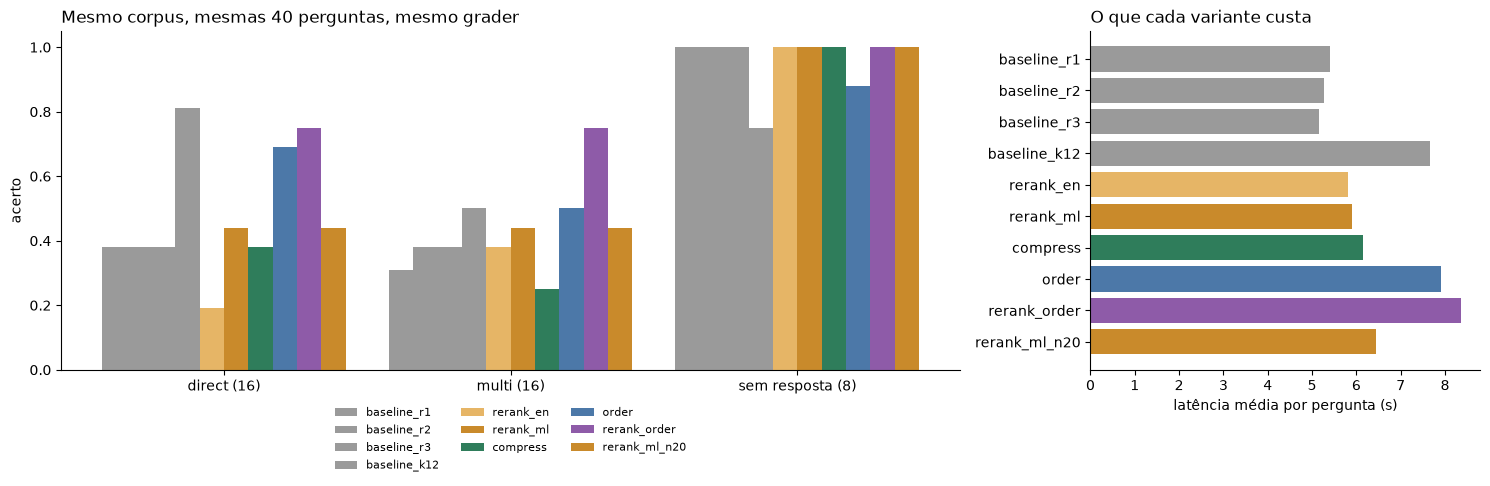

arquivos em results/: ['baseline_r1.csv', 'baseline_r2.csv', 'baseline_r3.csv', 'baseline_t03_r1.csv', 'baseline_t03_r2.csv', 'baseline_t03_r3.csv', 'disagreements_baseline_k12.csv', 'disagreements_baseline_t03_r1.csv', 'disagreements_baseline_t03_r2.csv', 'disagreements_baseline_t03_r3.csv', 'disagreements_compress.csv', 'disagreements_order.csv', 'disagreements_rerank_en.csv', 'disagreements_rerank_ml.csv', 'disagreements_rerank_ml_n20.csv', 'disagreements_rerank_order.csv', 'questions_used.json', 'results_all.csv', 'results_baseline_k12.csv', 'results_compress.csv', 'results_order.csv', 'results_rerank_en.csv', 'results_rerank_ml.csv', 'results_rerank_ml_n20.csv', 'results_rerank_order.csv', 'scoreboard.png', 'summary_table.csv']
download automático indisponível; pegue c:\Users\raimu\Documents\coding-projects\rag-f3-petrobras-vale\results_f3.zip no painel de arquivos. ModuleNotFoundError
⏱ 1.9 s


In [23]:
import matplotlib.pyplot as plt

def color_for(lab):
    if lab.startswith("baseline_t03"): return "#CFCFCF"
    if lab.startswith("baseline"):     return "#9A9A9A"
    if lab == "rerank_en":             return "#E6B566"
    if lab.startswith("rerank_order"): return "#8E5BA8"
    if lab.startswith("rerank"):       return "#C98A2B"
    if lab == "compress":              return "#2F7D5B"
    if lab == "order":                 return "#4C78A8"
    return "#666666"

def plot_comparison(summary, path=os.path.join(RESULTS_DIR, "scoreboard.png")):
    counts = pd.Series([q["tier"] for q in QUESTIONS]).value_counts().to_dict()
    tiers = ["direct", "multi", "none"]
    names = [f"direct ({counts.get('direct', 0)})", f"multi ({counts.get('multi', 0)})", f"sem resposta ({counts.get('none', 0)})"]
    labels = [l for l in summary.index if not l.startswith("baseline_t03")]
    x = np.arange(len(tiers)); w = 0.85 / len(labels)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [3, 1.3]})
    for j, lab in enumerate(labels):
        ax.bar(x + (j - (len(labels) - 1) / 2) * w, [summary.loc[lab, t] for t in tiers], w, color=color_for(lab), label=lab)
    ax.set_xticks(x); ax.set_xticklabels(names); ax.set_ylim(0, 1.05); ax.set_ylabel("acerto")
    ax.set_title(f"Mesmo corpus, mesmas {len(QUESTIONS)} perguntas, mesmo grader", loc="left")
    ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08))
    ax.spines[["top", "right"]].set_visible(False)
    ax2.barh(labels[::-1], [summary.loc[l, "latency_s"] for l in labels[::-1]], color=[color_for(l) for l in labels[::-1]])
    ax2.set_xlabel("latência média por pergunta (s)"); ax2.set_title("O que cada variante custa", loc="left")
    ax2.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); plt.savefig(path, dpi=200, bbox_inches="tight"); plt.show()

plot_comparison(summary)

pd.concat([RESULTS[l] for l in ALL_LABELS], ignore_index=True).to_csv(os.path.join(RESULTS_DIR, "results_all.csv"), index=False)
questions_out = os.path.join(RESULTS_DIR, "questions_used.json")
shutil.copy("questions.json", questions_out)
zip_path = shutil.make_archive("results_f3", "zip", RESULTS_DIR)
print("arquivos em results/:", sorted(os.listdir(RESULTS_DIR)))
try:
    from google.colab import files
    files.download(zip_path)
except Exception as e:
    print("download automático indisponível; pegue", zip_path, "no painel de arquivos.", type(e).__name__)

---
## Para o paper e os slides
| Seção | De onde sai |
|---|---|
| Corpus e perguntas | tiers e validação da célula "Corpus e perguntas"; os avisos sobre m05 e m06 |
| Diagnóstico do baseline | 1c (ruído entre rodadas), 1d (linhas erradas k=4), 1e (zona do gold, k=12) |
| Exemplos na tela | `rank_table` (Bloco 2), antes/depois da compressão (Bloco 3) |
| Comparação | `summary_table.csv` (Bloco 7) |
| Divergências com causa | `disagreements_<variante>.csv` |
| Sinal × ruído | amplitude entre r1-r3 e entre as rodadas a temperatura 0,3 (Bloco 6) |
| Limitações | 40 perguntas (1 pergunta = 2,5 pontos), 8 sem resposta, gold por documento, gerador de 3B, cross-encoder com limite de 512 subtokens |